In [3]:
import pandas as pd

# Replace with your downloaded CSV filename
df = pd.read_csv("Bank_Personal_Loan_Modelling.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df["Personal Loan"].value_counts())

(5000, 14)
   ID  Age  Experience  Income  ZIP Code  Family  CCAvg  Education  Mortgage  \
0   1   25           1      49     91107       4    1.6          1         0   
1   2   45          19      34     90089       3    1.5          1         0   
2   3   39          15      11     94720       1    1.0          1         0   
3   4   35           9     100     94112       1    2.7          2         0   
4   5   35           8      45     91330       4    1.0          2         0   

   Personal Loan  Securities Account  CD Account  Online  CreditCard  
0              0                   1           0       0           0  
1              0                   1           0       0           0  
2              0                   0           0       0           0  
3              0                   0           0       0           0  
4              0                   0           0       0           1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data col

Income statistics by loan acceptance (0 = No, 1 = Yes):
               count    mean  median  min  max
Personal Loan                                 
0               4520   66.24    59.0    8  224
1                480  144.75   142.5   60  203

Loan acceptance by income band:
             Customers  Accepted  Acceptance_rate
Income_band                                      
0–25               672         0             0.00
25–50             1242         0             0.00
50–75             1044         7             0.67
75–100             830        35             4.22
100–150            770       220            28.57
>150               442       218            49.32


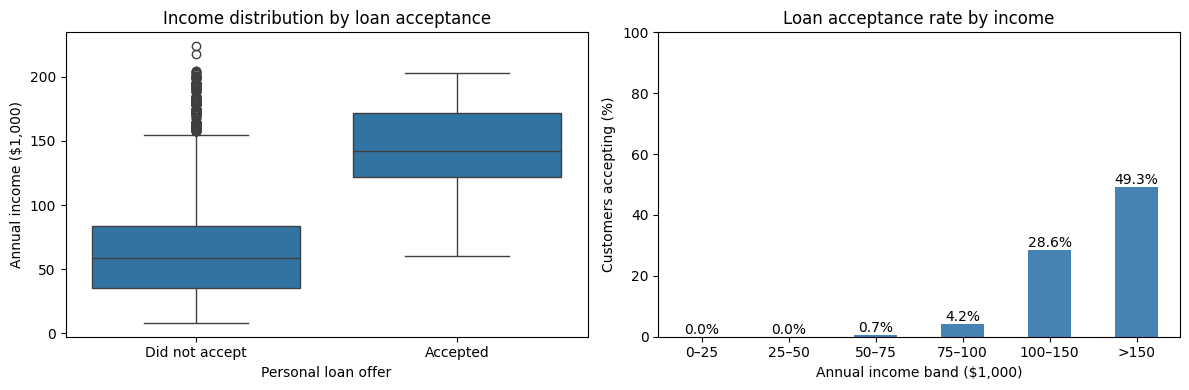

In [4]:
# Exploratory Data Analysis: Income vs Personal Loan Acceptance
#
# Objective:
# Examine how customers' annual income is associated with their
# likelihood of accepting a personal loan offer.
#
# Variables:
# - Income: Annual income in thousands of US dollars.
# - Personal Loan: 1 = accepted the offer; 0 = did not accept.
#
# Approach:
# 1. Compare income summary statistics between the two groups.
# 2. Calculate the percentage accepting within each income band.
# 3. Plot income distributions and acceptance rates.
#
# Interpretation:
# Acceptance rates account for differences in group sizes.
# Any observed trends indicate association, not causation.
#
# Prerequisite:
# The dataset has already been loaded into a DataFrame named df.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# 1. Compare income statistics by loan acceptance.
income_stats = (
    df.groupby("Personal Loan")["Income"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("Income statistics by loan acceptance (0 = No, 1 = Yes):")
print(income_stats)


# 2. Group customers into annual income bands.
# Intervals include the upper boundary: e.g., 25–50 means >25 to <=50.
income_band = pd.cut(
    df["Income"],
    bins=[0, 25, 50, 75, 100, 150, float("inf")],
    labels=["0–25", "25–50", "50–75", "75–100", "100–150", ">150"],
    include_lowest=True
)

# Create a separate DataFrame, preserving the original df.
income_eda = df.assign(Income_band=income_band)


# 3. Calculate customer counts, acceptances and acceptance rates.
# For a binary target, its mean equals the proportion accepting.
summary = (
    income_eda.groupby("Income_band", observed=True)["Personal Loan"]
    .agg(
        Customers="size",
        Accepted="sum",
        Acceptance_rate="mean"
    )
)

# Convert the acceptance proportion into a percentage.
summary["Acceptance_rate"] *= 100

print("\nLoan acceptance by income band:")
print(summary.round(2))


# 4. Create two plots to examine the relationship.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Boxplot: compare income distributions between the two groups.
sns.boxplot(
    data=df,
    x="Personal Loan",
    y="Income",
    ax=axes[0]
)

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Did not accept", "Accepted"])
axes[0].set_xlabel("Personal loan offer")
axes[0].set_ylabel("Annual income ($1,000)")
axes[0].set_title("Income distribution by loan acceptance")

# Bar chart: compare acceptance percentages across income bands.
summary["Acceptance_rate"].plot.bar(
    ax=axes[1],
    color="steelblue",
    rot=0
)

axes[1].set_xlabel("Annual income band ($1,000)")
axes[1].set_ylabel("Customers accepting (%)")
axes[1].set_title("Loan acceptance rate by income")
axes[1].set_ylim(0, 100)

# Add percentage labels above the bars.
for position, rate in enumerate(summary["Acceptance_rate"]):
    axes[1].text(
        position,
        rate + 1,
        f"{rate:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


Overall loan acceptance rate: 9.60%

Feature: Age
Missing values: 0

Summary statistics by loan acceptance:
               count   mean  median  min  max
Personal Loan                                
0               4520  45.37    45.0   23   67
1                480  45.07    45.0   26   65

Acceptance by feature range:
                Customers  Accepted  Acceptance_rate
Group                                               
(22.999, 34.0]       1123       118            10.51
(34.0, 42.0]          999        88             8.81
(42.0, 50.0]         1008       100             9.92
(50.0, 57.0]          921        86             9.34
(57.0, 67.0]          949        88             9.27


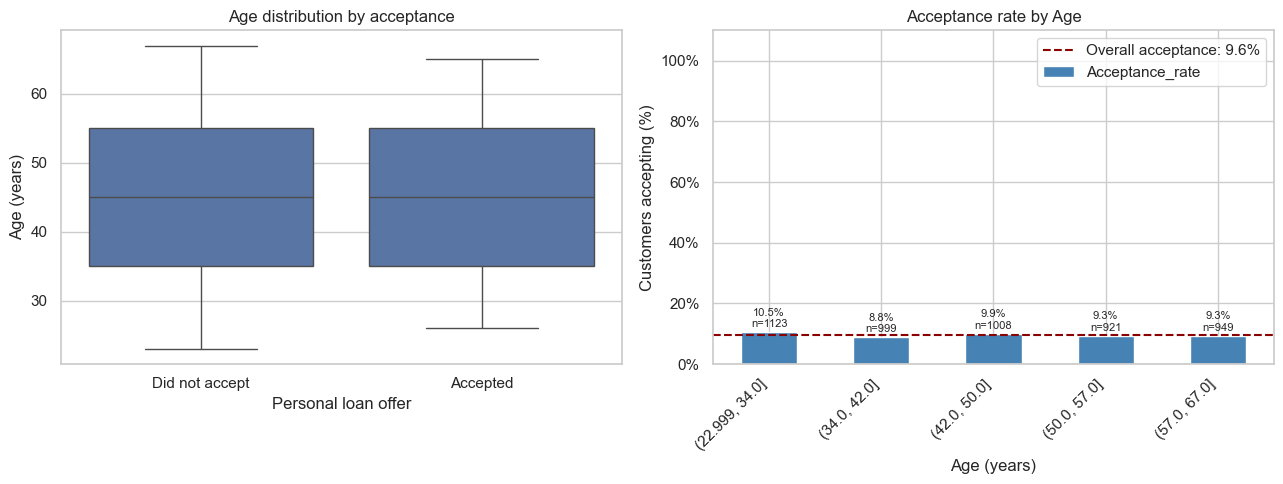


Feature: Experience
Missing values: 0

Summary statistics by loan acceptance:
               count   mean  median  min  max
Personal Loan                                
0               4520  20.13    20.0   -3   43
1                480  19.84    20.0    0   41

Data quality check: 52 negative values in Experience; investigate before modelling.

Acceptance by feature range:
               Customers  Accepted  Acceptance_rate
Group                                              
(-3.001, 8.0]       1024       106            10.35
(8.0, 17.0]         1098       102             9.29
(17.0, 24.0]         932        88             9.44
(24.0, 32.0]        1047       100             9.55
(32.0, 43.0]         899        84             9.34


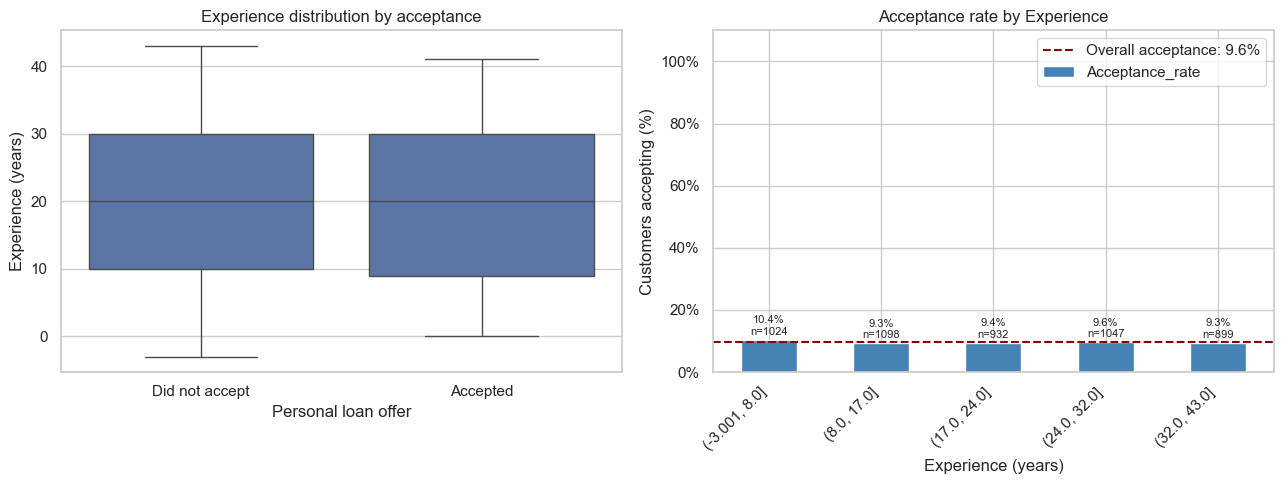


Feature: Income
Missing values: 0

Summary statistics by loan acceptance:
               count    mean  median  min  max
Personal Loan                                 
0               4520   66.24    59.0    8  224
1                480  144.75   142.5   60  203

Acceptance by feature range:
                Customers  Accepted  Acceptance_rate
Group                                               
(7.999, 33.0]        1029         0             0.00
(33.0, 52.0]          973         0             0.00
(52.0, 78.0]         1017         7             0.69
(78.0, 113.0]        1002        77             7.68
(113.0, 224.0]        979       396            40.45


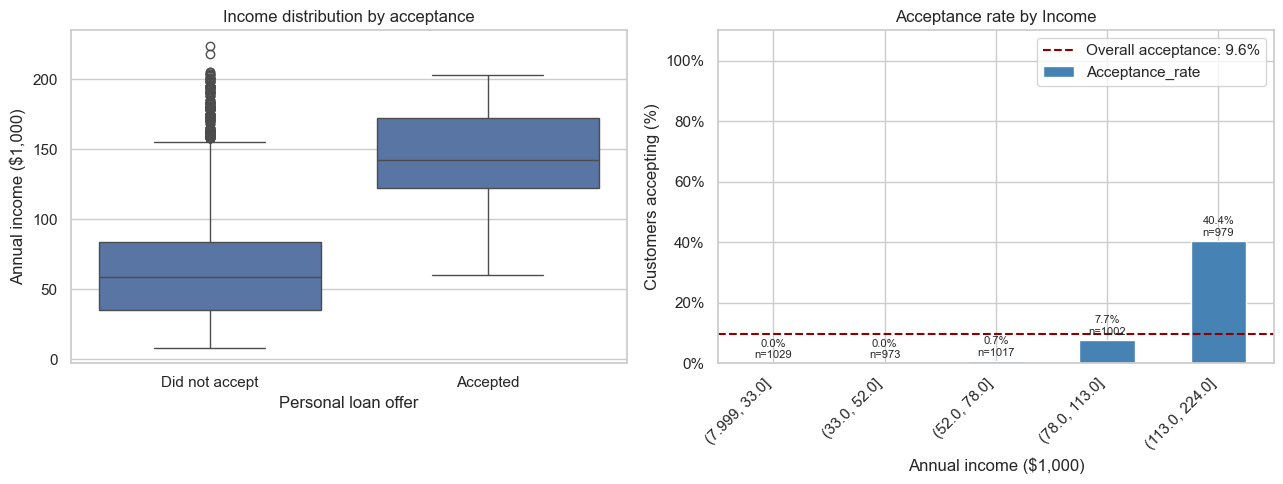


Feature: ZIP Code
Missing values: 0

Showing the 15 most frequent ZIP codes only.

Acceptance by category:
       Customers  Accepted  Acceptance_rate
Group                                      
94720        169        19            11.24
94305        127        13            10.24
95616        116         6             5.17
90095         71         8            11.27
93106         57         4             7.02
92037         54         5             9.26
93943         54         4             7.41
91320         53         2             3.77
94025         52         4             7.69
91711         52         4             7.69
92093         51         9            17.65
90245         50         5            10.00
90024         50         1             2.00
91330         46         3             6.52
90089         46         8            17.39


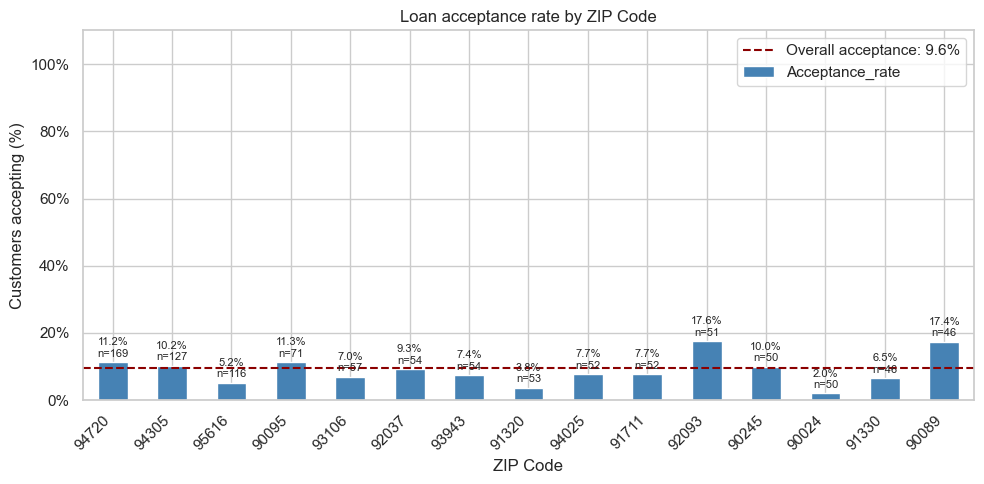


Feature: Family
Missing values: 0

Acceptance by category:
       Customers  Accepted  Acceptance_rate
Group                                      
1           1472       107             7.27
2           1296       106             8.18
3           1010       133            13.17
4           1222       134            10.97


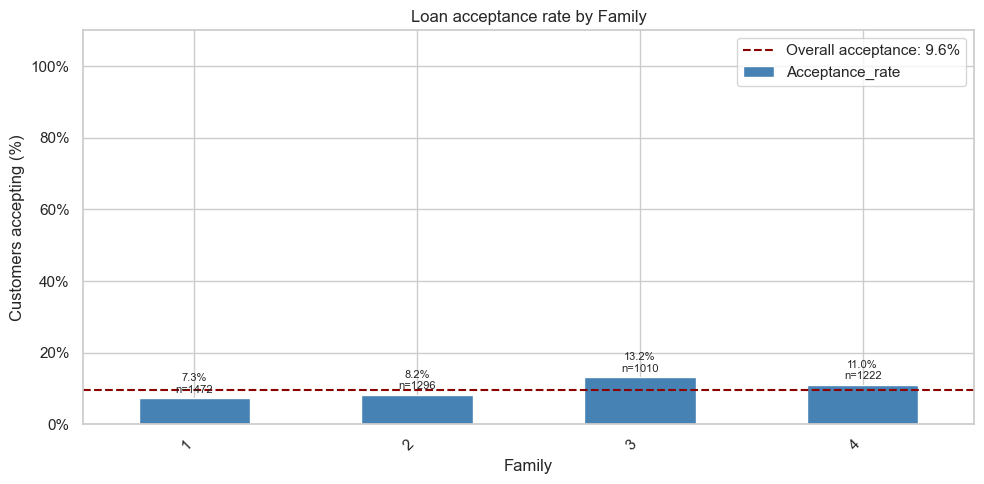


Feature: CCAvg
Missing values: 0

Summary statistics by loan acceptance:
               count  mean  median  min   max
Personal Loan                                
0               4520  1.73     1.4  0.0   8.8
1                480  3.91     3.8  0.0  10.0

Acceptance by feature range:
               Customers  Accepted  Acceptance_rate
Group                                              
(-0.001, 0.5]       1076        29             2.70
(0.5, 1.2]           988        33             3.34
(1.2, 1.9]           995        30             3.02
(1.9, 2.8]           985        47             4.77
(2.8, 10.0]          956       341            35.67


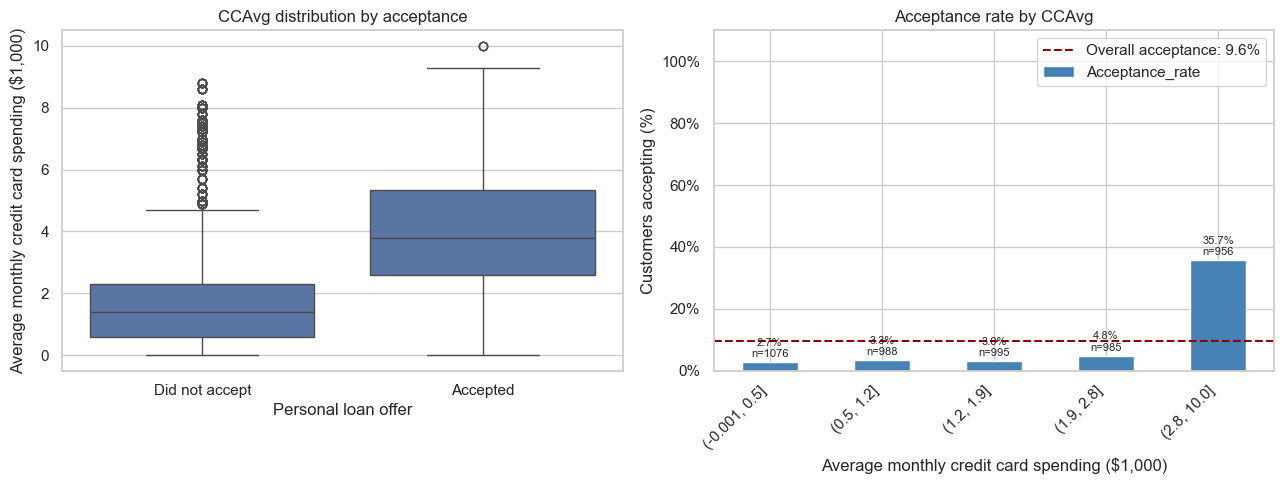


Feature: Education
Missing values: 0

Acceptance by category:
                       Customers  Accepted  Acceptance_rate
Group                                                      
Advanced/professional       1501       205            13.66
Graduate                    1403       182            12.97
Undergraduate               2096        93             4.44


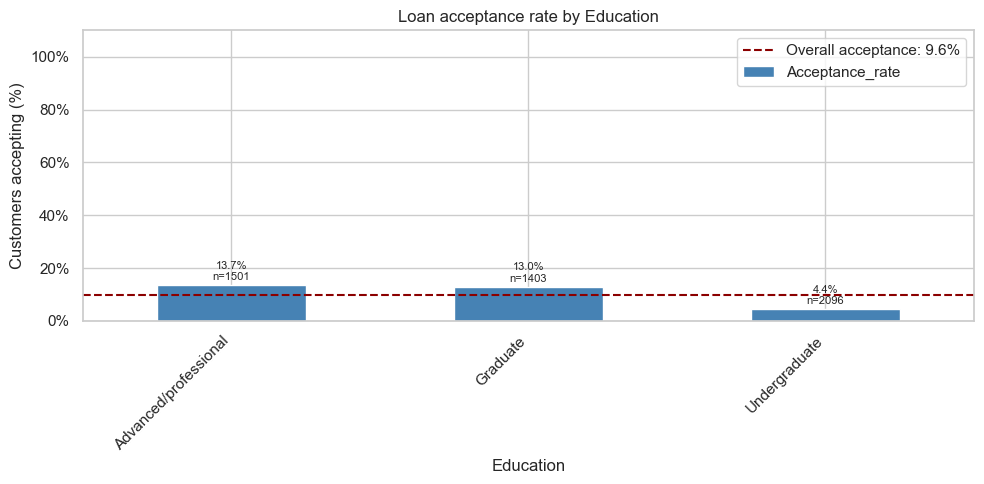


Feature: Mortgage
Missing values: 0

Summary statistics by loan acceptance:
               count    mean  median  min  max
Personal Loan                                 
0               4520   51.79     0.0    0  635
1                480  100.85     0.0    0  617

Acceptance by feature range:
                 Customers  Accepted  Acceptance_rate
Group                                                
No mortgage           3462       312             9.01
(74.999, 109.0]        391        15             3.84
(109.0, 153.0]         386        21             5.44
(153.0, 227.0]         378        29             7.67
(227.0, 635.0]         383       103            26.89


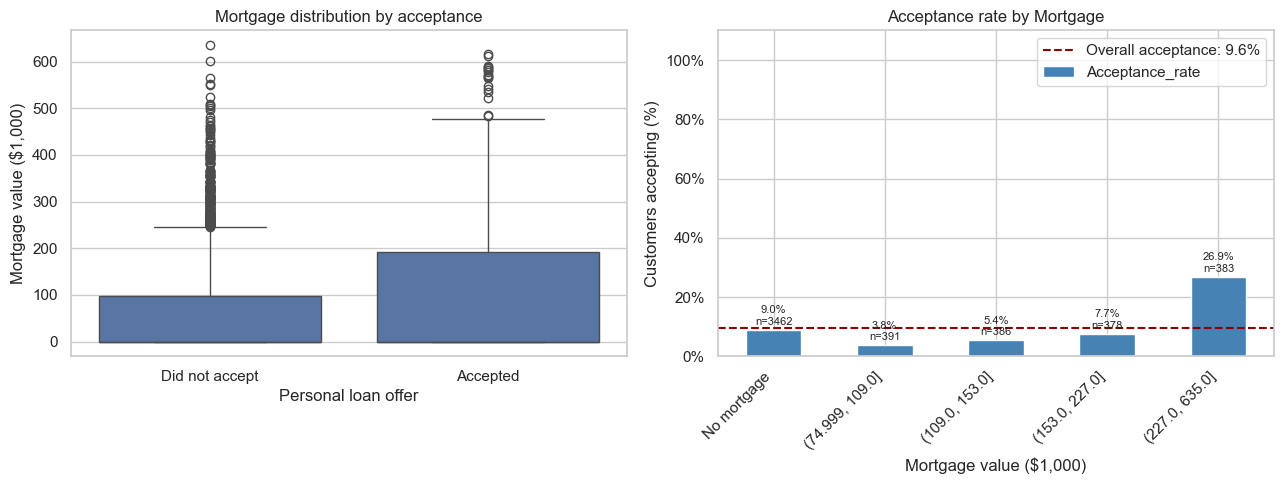


Feature: Securities Account
Missing values: 0

Acceptance by category:
       Customers  Accepted  Acceptance_rate
Group                                      
No          4478       420             9.38
Yes          522        60            11.49


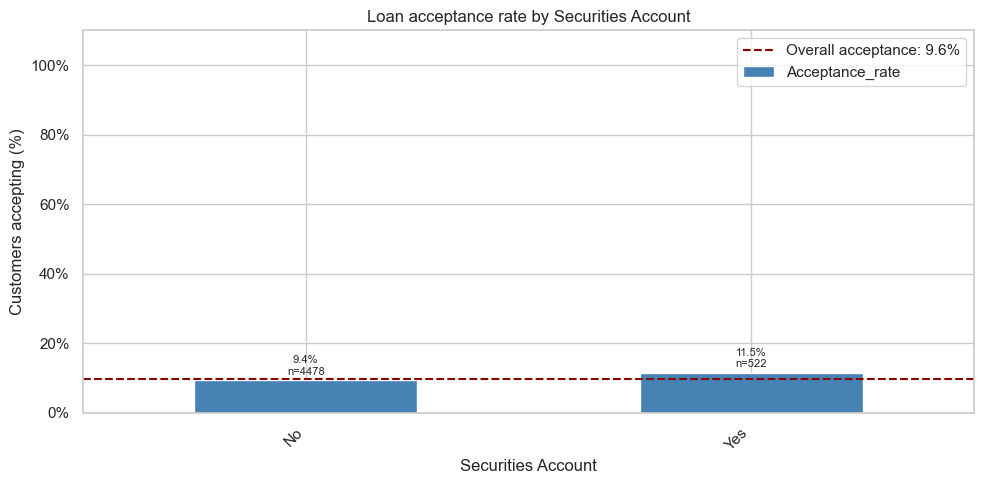


Feature: CD Account
Missing values: 0

Acceptance by category:
       Customers  Accepted  Acceptance_rate
Group                                      
No          4698       340             7.24
Yes          302       140            46.36


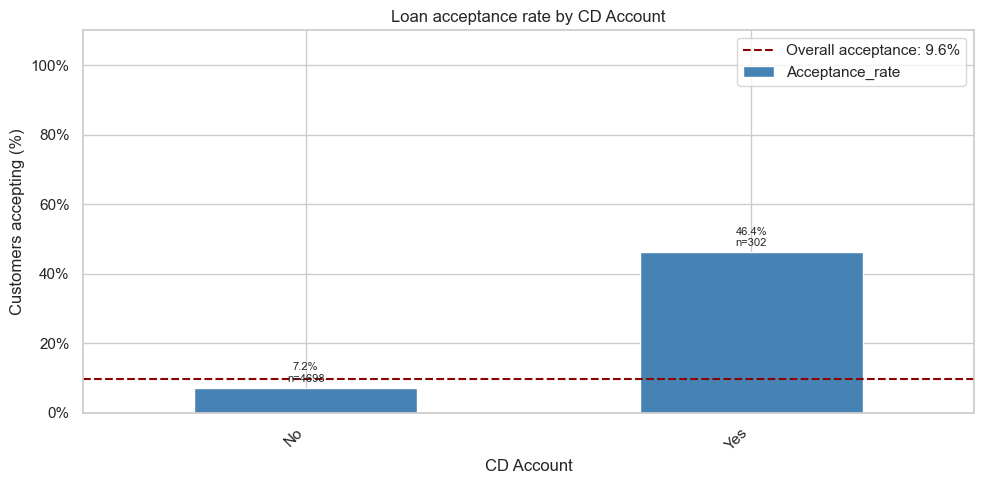


Feature: Online
Missing values: 0

Acceptance by category:
       Customers  Accepted  Acceptance_rate
Group                                      
No          2016       189             9.38
Yes         2984       291             9.75


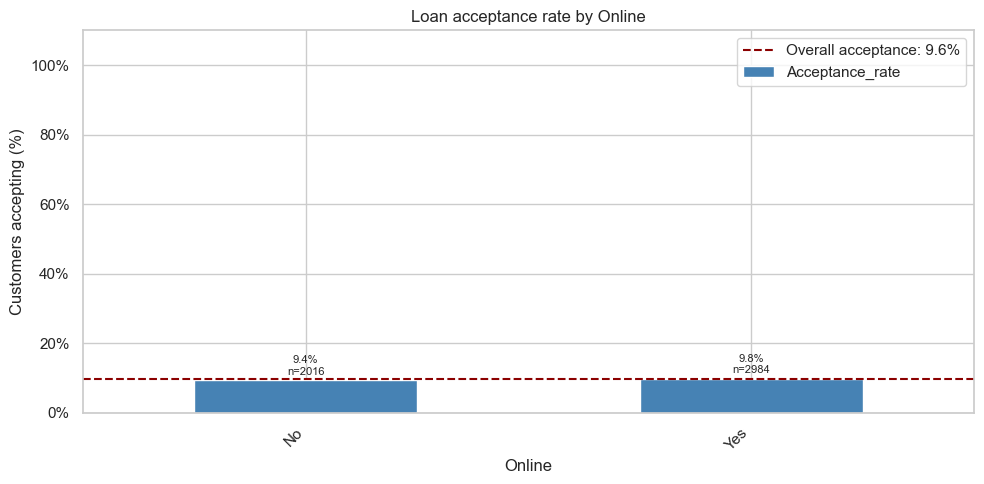


Feature: CreditCard
Missing values: 0

Acceptance by category:
       Customers  Accepted  Acceptance_rate
Group                                      
No          3530       337             9.55
Yes         1470       143             9.73


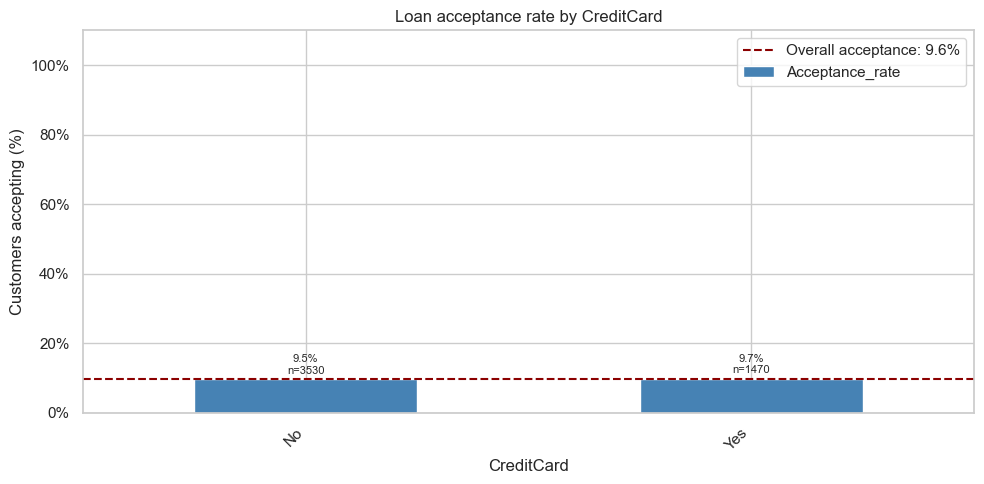

In [10]:
# Exploratory Data Analysis: All Features vs Personal Loan Acceptance
#
# Objective:
# Explore how each customer characteristic is associated with
# accepting a personal loan offer.
#
# Target:
# - Personal Loan: 1 = accepted; 0 = did not accept.
#
# Approach:
# 1. For continuous features:
#    - Compare distributions using boxplots.
#    - Divide values into approximately equal-sized groups and
#      calculate the acceptance rate within each group.
# 2. For categorical features:
#    - Calculate acceptance rates for each category.
# 3. Print customer counts alongside acceptance rates so that
#    trends based on small groups can be identified.
#
# Important:
# - Integer columns are not necessarily continuous measurements:
#   Education, Online and account indicators represent categories.
# - ID is excluded because it is a customer identifier.
# - ZIP Code is treated as a category, not a numeric measurement.
#   Only its 15 most frequent categories are plotted for readability.
# - These plots show association, not causation.
# - This code does not modify the original DataFrame.
#
# Prerequisite:
# The dataset is already loaded into a DataFrame named df.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")

target = "Personal Loan"

# Explicitly identify continuous measurements.
continuous_features = [
    "Age",
    "Experience",
    "Income",
    "CCAvg",
    "Mortgage"
]

# All remaining features are treated as categorical.
features = [
    column for column in df.columns
    if column not in [target, "ID"]
]

# Readable labels for coded categories.
category_labels = {
    "Education": {
        1: "Undergraduate",
        2: "Graduate",
        3: "Advanced/professional"
    },
    "Securities Account": {0: "No", 1: "Yes"},
    "CD Account": {0: "No", 1: "Yes"},
    "Online": {0: "No", 1: "Yes"},
    "CreditCard": {0: "No", 1: "Yes"}
}

# Units for continuous features.
axis_labels = {
    "Age": "Age (years)",
    "Experience": "Experience (years)",
    "Income": "Annual income ($1,000)",
    "CCAvg": "Average monthly credit card spending ($1,000)",
    "Mortgage": "Mortgage value ($1,000)"
}


def acceptance_summary(data, group_column):
    """Calculate counts and acceptance percentages for each group."""
    summary = (
        data.groupby(group_column, observed=True)[target]
        .agg(
            Customers="count",
            Accepted="sum",
            Acceptance_rate="mean"
        )
    )

    summary["Acceptance_rate"] *= 100
    return summary


def plot_acceptance_rates(summary, ax, xlabel, title):
    """Plot group acceptance rates and label each bar with its sample size."""
    summary["Acceptance_rate"].plot.bar(
        ax=ax,
        color="steelblue",
        rot=45
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Customers accepting (%)")
    ax.set_title(title)
    ax.set_ylim(0, 110)  # Extra space for labels above the bars.
    ax.set_yticks(range(0, 101, 20))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plt.setp(ax.get_xticklabels(), ha="right")

    for position, (_, row) in enumerate(summary.iterrows()):
        ax.text(
            position,
            row["Acceptance_rate"] + 1,
            f'{row["Acceptance_rate"]:.1f}%\n'
            f'n={int(row["Customers"])}',
            ha="center",
            va="bottom",
            fontsize=8
        )


# Overall acceptance rate provides a reference for every plot.
overall_rate = df[target].mean() * 100
print(f"Overall loan acceptance rate: {overall_rate:.2f}%")


# Loop through all features except the target and customer ID.
for feature in features:

    print(f"\n{'=' * 65}")
    print(f"Feature: {feature}")
    print(f"Missing values: {df[feature].isna().sum()}")

    # Use complete observations for this feature and the target.
    data = df[[feature, target]].dropna().copy()

    if data.empty:
        print("Skipped: no complete observations.")
        continue

    if feature in continuous_features:

        # Print descriptive statistics for accepted/non-accepted groups.
        print("\nSummary statistics by loan acceptance:")
        print(
            data.groupby(target)[feature]
            .agg(["count", "mean", "median", "min", "max"])
            .round(2)
        )

        # Flag impossible negative measurements without silently removing them.
        negative_count = (data[feature] < 0).sum()
        if negative_count:
            print(
                f"\nData quality check: {negative_count} negative "
                f"values in {feature}; investigate before modelling."
            )

        # Mortgage commonly contains many zeros. Separate customers with
        # no mortgage, then bin positive mortgage values independently.
        if feature == "Mortgage":
            groups = pd.Series(index=data.index, dtype="object")
            groups.loc[data[feature] == 0] = "No mortgage"

            positive = data[feature] > 0

            if positive.any():
                positive_bins = pd.qcut(
                    data.loc[positive, feature],
                    q=4,
                    duplicates="drop"
                )

                # Handle the edge case where positive values are constant.
                if positive_bins.notna().any():
                    groups.loc[positive] = positive_bins.astype(str)
                else:
                    groups.loc[positive] = "Positive mortgage"

            groups.loc[data[feature] < 0] = "Negative: check data"

            # Preserve a meaningful order for the groups.
            order = []
            if (data[feature] == 0).any():
                order.append("No mortgage")

            if positive.any():
                if positive_bins.notna().any():
                    order.extend(
                        str(interval)
                        for interval in positive_bins.cat.categories
                    )
                else:
                    order.append("Positive mortgage")

            if (data[feature] < 0).any():
                order.append("Negative: check data")

            data["Group"] = pd.Categorical(
                groups, categories=order, ordered=True
            )

        else:
            # Quantile bins contain approximately equal customer counts.
            # Duplicate boundaries are removed when many values are identical.
            if data[feature].nunique() > 1:
                data["Group"] = pd.qcut(
                    data[feature],
                    q=5,
                    duplicates="drop"
                )
            else:
                data["Group"] = "All customers"

        summary = acceptance_summary(data, "Group")

        print("\nAcceptance by feature range:")
        print(summary.round(2))

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))

        sns.boxplot(
            data=data,
            x=target,
            y=feature,
            order=[0, 1],
            ax=axes[0]
        )

        axes[0].set_xticks([0, 1])
        axes[0].set_xticklabels(["Did not accept", "Accepted"])
        axes[0].set_xlabel("Personal loan offer")
        axes[0].set_ylabel(axis_labels.get(feature, feature))
        axes[0].set_title(f"{feature} distribution by acceptance")

        plot_acceptance_rates(
            summary,
            axes[1],
            axis_labels.get(feature, feature),
            f"Acceptance rate by {feature}"
        )

        rate_ax = axes[1]

    else:

        # Convert numeric category codes into readable labels where available.
        if feature in category_labels:
            data["Group"] = data[feature].replace(
                category_labels[feature]
            )
        else:
            data["Group"] = data[feature]

        summary = acceptance_summary(data, "Group")

        # ZIP codes can contain many categories; show the most common 15.
        # The full summary is retained locally before selecting plot categories.
        if feature == "ZIP Code":
            summary = summary.sort_values(
                "Customers", ascending=False
            ).head(15)

            print("\nShowing the 15 most frequent ZIP codes only.")

        print("\nAcceptance by category:")
        print(summary.round(2))

        fig, rate_ax = plt.subplots(figsize=(10, 5))

        plot_acceptance_rates(
            summary,
            rate_ax,
            feature,
            f"Loan acceptance rate by {feature}"
        )

    # Add the overall acceptance rate as a comparison line.
    rate_ax.axhline(
        overall_rate,
        color="darkred",
        linestyle="--",
        label=f"Overall acceptance: {overall_rate:.1f}%"
    )
    rate_ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

Feature correlations with loan acceptance:
                    Pearson_r  Absolute_r
Income                  0.497       0.497
CCAvg                   0.366       0.366
CD Account              0.337       0.337
Mortgage                0.140       0.140
Family                  0.063       0.063
Securities Account      0.031       0.031
Experience             -0.025       0.025
Age                    -0.019       0.019
Online                  0.010       0.010
CreditCard              0.010       0.010


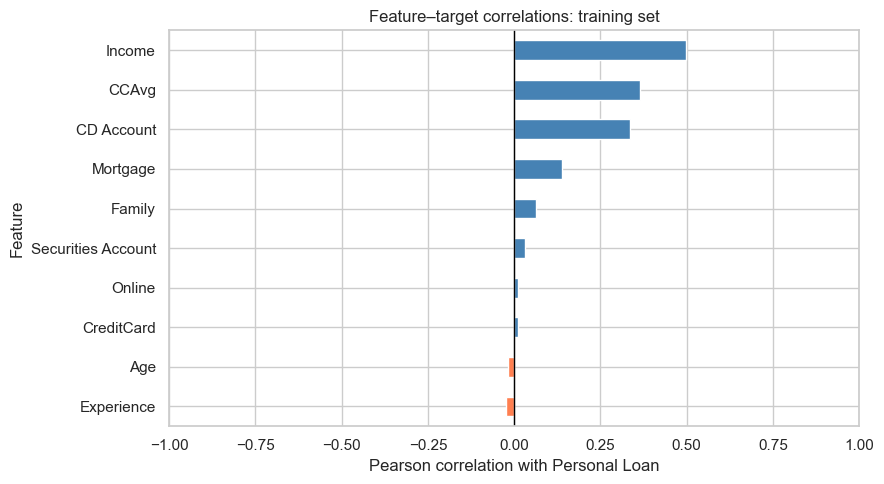

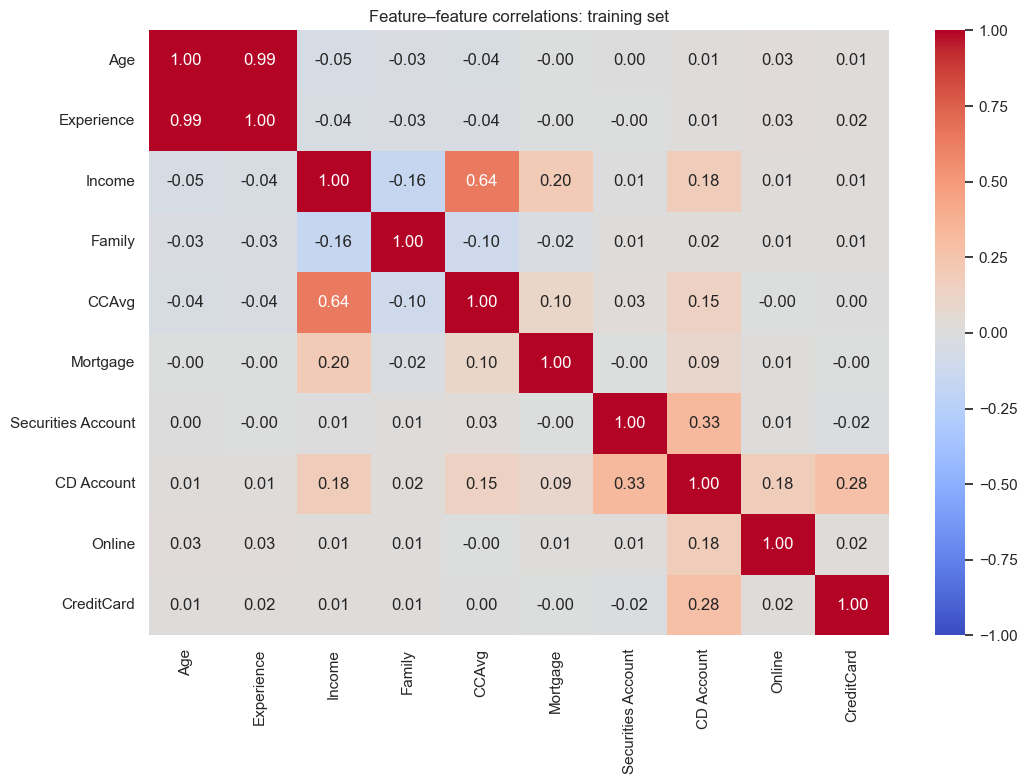

In [11]:
# Filter Methods: Pearson Correlation
#
# Objective:
# Examine linear associations with loan acceptance and identify
# potentially redundant numerical features.
#
# Approach:
# 1. Split the data into training and test sets.
# 2. Calculate feature–target correlations on the training set.
# 3. Plot correlations among numerical features.
#
# Interpretation:
# - Positive correlation: higher values are associated with acceptance.
# - Negative correlation: higher values are associated with non-acceptance.
# - Near-zero correlation: little linear association; nonlinear
#   relationships may still exist.
#
# Important:
# - Personal Loan is binary, so Pearson correlation with a continuous
#   feature is equivalent to point-biserial correlation.
# - Exclude ID and ZIP Code because their numeric values are identifiers.
# - Exclude Education here because its codes represent categories.
# - Do not remove features solely because their target correlation is low.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Separate predictors from the target.
X = df.drop(columns=["Personal Loan", "ID", "ZIP Code"])
y = df["Personal Loan"]

# Preserve approximately the same acceptance proportion in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 2. Select numerical measurements and binary indicators.
# Family is treated as a numerical count for this analysis.
correlation_features = [
    "Age",
    "Experience",
    "Income",
    "Family",
    "CCAvg",
    "Mortgage",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard"
]

# Create a separate analysis table containing training data only.
train_eda = X_train[correlation_features].copy()
train_eda["Personal Loan"] = y_train

# Treat impossible negative experience values as missing for this analysis.
# Pandas excludes missing pairs when calculating each correlation.
train_eda.loc[train_eda["Experience"] < 0, "Experience"] = float("nan")

correlation_matrix = train_eda.corr(method="pearson")

# Rank features by correlation magnitude, retaining the original sign.
target_correlations = (
    correlation_matrix["Personal Loan"]
    .drop("Personal Loan")
)

ranking = target_correlations.to_frame(name="Pearson_r")
ranking["Absolute_r"] = ranking["Pearson_r"].abs()
ranking = ranking.sort_values("Absolute_r", ascending=False)

print("Feature correlations with loan acceptance:")
print(ranking.round(3))

# 3. Plot feature–target correlations.
plt.figure(figsize=(9, 5))

ordered = ranking["Pearson_r"].sort_values()
colors = ["steelblue" if value >= 0 else "coral" for value in ordered]

ordered.plot.barh(color=colors)

plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1, 1)
plt.xlabel("Pearson correlation with Personal Loan")
plt.ylabel("Feature")
plt.title("Feature–target correlations: training set")
plt.tight_layout()
plt.show()

# 4. Plot feature–feature correlations to examine redundancy.
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix.loc[correlation_features, correlation_features],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature–feature correlations: training set")
plt.tight_layout()
plt.show()

Mutual information with personal loan acceptance:
Income                0.1305
CCAvg                 0.0917
CD Account            0.0341
Mortgage              0.0223
Education             0.0121
Age                   0.0035
Family                0.0027
Securities Account    0.0004
Online                0.0001
CreditCard            0.0001
Experience            0.0000
Name: Mutual_information, dtype: float64


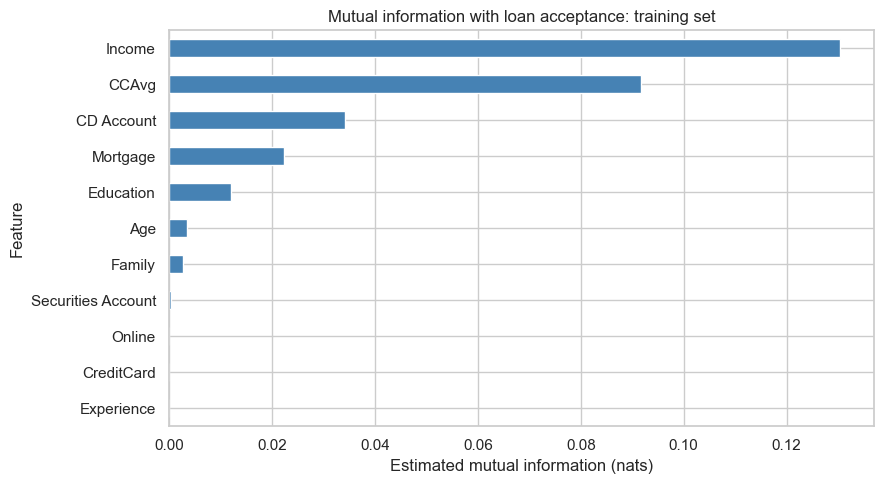

In [15]:
# Filter Methods: Mutual Information
#
# Objective:
# Measure how informative each feature is about personal loan acceptance,
# including relationships that Pearson correlation may miss.
#
# Approach:
# 1. Use the training data only.
# 2. Identify continuous measurements and discrete categories/counts.
# 3. Estimate mutual information between each feature and the target.
# 4. Rank and plot the resulting scores.
#
# Interpretation:
# - Higher scores indicate stronger individual dependence on the target.
# - A score of zero means the estimator detected no dependence;
#   it does not prove that the feature is useless.
# - Scores do not indicate the direction of a relationship.
# - MI measures each feature separately, so it does not account for
#   redundancy between features or effects requiring feature combinations.
#
# Prerequisite:
# X_train and y_train were created using the previous train/test split.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif

# 1. Copy the training features to preserve the original data.
X_mi = X_train.copy()

# Negative work experience is invalid; treat it as missing.
X_mi.loc[X_mi["Experience"] < 0, "Experience"] = float("nan")

# 2. Specify discrete features explicitly.
# Family is a count; the remaining features are categorical indicators.
# Age and Experience are treated as continuous measurements even though
# their recorded values are integers.
discrete_features = [
    "Family",
    "Education",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard"
]

continuous_features = [
    column for column in X_mi.columns
    if column not in discrete_features
]

# 3. Fill missing values using training-set information only.
# Continuous measurements: median.
# Discrete features: most frequent value.
continuous_imputer = SimpleImputer(strategy="median")
discrete_imputer = SimpleImputer(strategy="most_frequent")

X_mi[continuous_features] = continuous_imputer.fit_transform(
    X_mi[continuous_features]
)

X_mi[discrete_features] = discrete_imputer.fit_transform(
    X_mi[discrete_features]
)

# Mark each column as discrete (True) or continuous (False).
discrete_mask = [
    column in discrete_features
    for column in X_mi.columns
]

# 4. Estimate mutual information with the binary target.
# Scaling and one-hot encoding are not needed for this calculation.
mi_values = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    n_neighbors=3,
    random_state=42
)

# 5. Rank features by their MI scores.
mi_scores = pd.Series(
    mi_values,
    index=X_mi.columns,
    name="Mutual_information"
).sort_values(ascending=False)

print("Mutual information with personal loan acceptance:")
print(mi_scores.round(4))

# 6. Plot the scores.
plt.figure(figsize=(9, 5))

mi_scores.sort_values().plot.barh(color="steelblue")

plt.xlabel("Estimated mutual information (nats)")
plt.ylabel("Feature")
plt.title("Mutual information with loan acceptance: training set")
plt.tight_layout()
plt.show()

In [16]:
# Logistic Regression: Stratified 10-Fold Cross-Validation
#
# Objective:
# Predict whether a customer will accept a personal loan offer using
# the five selected features.
#
# Approach:
# 1. Standardise Income, CCAvg and Mortgage.
# 2. One-hot encode Education because its numbers represent categories.
# 3. Keep CD Account as a binary predictor.
# 4. Evaluate logistic regression using stratified 10-fold CV.
#
# Leakage prevention:
# Preprocessing is fitted separately within each training fold.
# The existing held-out test set is not used during cross-validation.
#
# Metrics:
# Accuracy, precision, recall and F1 use a probability threshold of 0.5.
# ROC-AUC and average precision use predicted probabilities.
#
# Prerequisite:
# X_train, X_test, y_train and y_test already exist.

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

selected_features = [
    "Income",
    "CCAvg",
    "CD Account",
    "Mortgage",
    "Education"
]

X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

# Continuous measurements: fill missing values, then standardise.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Education: fill missing values, then create category indicators.
education_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

# CD Account is already coded as 0/1.
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, ["Income", "CCAvg", "Mortgage"]),
    ("education", education_pipeline, ["Education"]),
    ("binary", binary_pipeline, ["CD Account"])
])

# Combine preprocessing and modelling in one pipeline.
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        C=1.0,
        max_iter=2000
    ))
])

# Each observation is used for validation exactly once.
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

results = cross_validate(
    model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    error_score="raise"
)

# Display validation results for each fold.
fold_scores = pd.DataFrame({
    metric: results[f"test_{metric}"]
    for metric in scoring
})

fold_scores.index = range(1, 11)
fold_scores.index.name = "Fold"

print("Validation scores for each fold:")
print(fold_scores.round(3))

# Mean indicates average performance.
# Standard deviation indicates variation across the validation folds.
summary = fold_scores.agg(["mean", "std"]).T

print("\nCross-validation summary:")
print(summary.round(3))

Validation scores for each fold:
      accuracy  precision  recall     f1  roc_auc  average_precision
Fold                                                                
1        0.970      0.933   0.737  0.824    0.963              0.902
2        0.958      0.920   0.605  0.730    0.976              0.877
3        0.955      0.857   0.632  0.727    0.960              0.860
4        0.960      0.824   0.737  0.778    0.945              0.823
5        0.968      0.931   0.711  0.806    0.950              0.849
6        0.952      0.828   0.632  0.716    0.934              0.800
7        0.955      0.920   0.590  0.719    0.963              0.812
8        0.952      0.917   0.564  0.698    0.960              0.825
9        0.925      0.696   0.410  0.516    0.919              0.647
10       0.950      0.806   0.641  0.714    0.945              0.816

Cross-validation summary:
                    mean    std
accuracy           0.954  0.012
precision          0.863  0.077
recall          

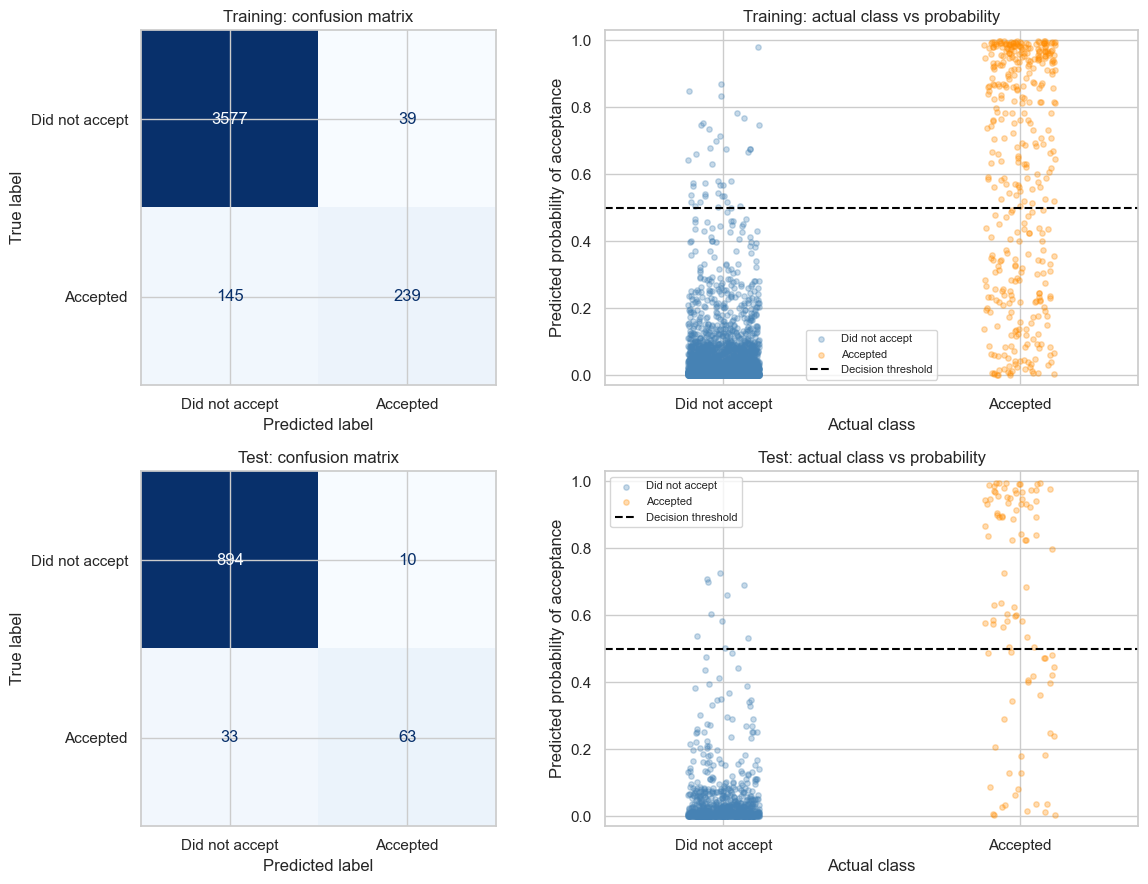

Training and held-out test metrics:
          Accuracy  Precision  Recall     F1  ROC-AUC  Average precision
Dataset                                                                 
Training     0.954      0.860   0.622  0.722    0.952              0.825
Test         0.957      0.863   0.656  0.746    0.946              0.836


In [17]:
# Logistic Regression: Training and Test Prediction Plots
#
# Objective:
# Compare predictions with actual loan acceptance for the training
# and held-out test datasets.
#
# Plots:
# 1. Confusion matrices show correct and incorrect classifications.
# 2. Probability plots show predicted acceptance probabilities for
#    customers who actually accepted or did not accept.
#
# Interpretation:
# - Actual class 0: predicted probabilities should ideally be near 0.
# - Actual class 1: predicted probabilities should ideally be near 1.
# - The dashed line marks the classification threshold of 0.5.
#
# Important:
# Training predictions are in-sample and may appear better than test
# predictions. Use the test results for final evaluation, rather than
# repeatedly tuning the model based on them.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Fit preprocessing and logistic regression using training data only.
model.fit(X_train_selected, y_train)

datasets = {
    "Training": (X_train_selected, y_train),
    "Test": (X_test_selected, y_test)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
metric_rows = []

# Fixed seed makes the visual jitter reproducible.
rng = np.random.default_rng(42)

for row, (name, (X_data, y_data)) in enumerate(datasets.items()):

    # Predict class labels and probabilities of acceptance.
    predictions = model.predict(X_data)
    probabilities = model.predict_proba(X_data)[:, 1]

    # 1. Confusion matrix.
    ConfusionMatrixDisplay.from_predictions(
        y_data,
        predictions,
        labels=[0, 1],
        display_labels=["Did not accept", "Accepted"],
        cmap="Blues",
        colorbar=False,
        ax=axes[row, 0]
    )

    axes[row, 0].set_title(f"{name}: confusion matrix")

    # 2. Classification equivalent of a parity plot.
    # Horizontal jitter separates overlapping points visually.
    # It does not change the actual classes or model predictions.
    actual = np.asarray(y_data)
    jitter = rng.uniform(-0.12, 0.12, size=len(actual))

    for label, color, description in [
        (0, "steelblue", "Did not accept"),
        (1, "darkorange", "Accepted")
    ]:
        mask = actual == label

        axes[row, 1].scatter(
            actual[mask] + jitter[mask],
            probabilities[mask],
            color=color,
            alpha=0.3,
            s=15,
            label=description
        )

    axes[row, 1].axhline(
        0.5,
        color="black",
        linestyle="--",
        label="Decision threshold"
    )

    axes[row, 1].set_xticks([0, 1])
    axes[row, 1].set_xticklabels(["Did not accept", "Accepted"])
    axes[row, 1].set_xlim(-0.4, 1.4)
    axes[row, 1].set_ylim(-0.03, 1.03)
    axes[row, 1].set_xlabel("Actual class")
    axes[row, 1].set_ylabel("Predicted probability of acceptance")
    axes[row, 1].set_title(f"{name}: actual class vs probability")
    axes[row, 1].legend(fontsize=8)

    # Calculate metrics for the same predictions.
    metric_rows.append({
        "Dataset": name,
        "Accuracy": accuracy_score(y_data, predictions),
        "Precision": precision_score(
            y_data, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_data, predictions, zero_division=0
        ),
        "F1": f1_score(y_data, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_data, probabilities),
        "Average precision": average_precision_score(
            y_data, probabilities
        )
    })

plt.tight_layout()
plt.show()

metrics = pd.DataFrame(metric_rows).set_index("Dataset")

print("Training and held-out test metrics:")
print(metrics.round(3))

Best hyperparameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}

Best mean CV average precision: 0.899

Top five hyperparameter combinations:
 param_classifier__max_depth  param_classifier__min_samples_leaf  param_classifier__min_samples_split  mean_train_average_precision  mean_test_average_precision  std_test_average_precision
                           5                                  10                                    2                         0.918                        0.899                       0.040
                           5                                  10                                   20                         0.918                        0.899                       0.040
                           5                                   5                                   20                         0.919                        0.893                       0.038
                           5               

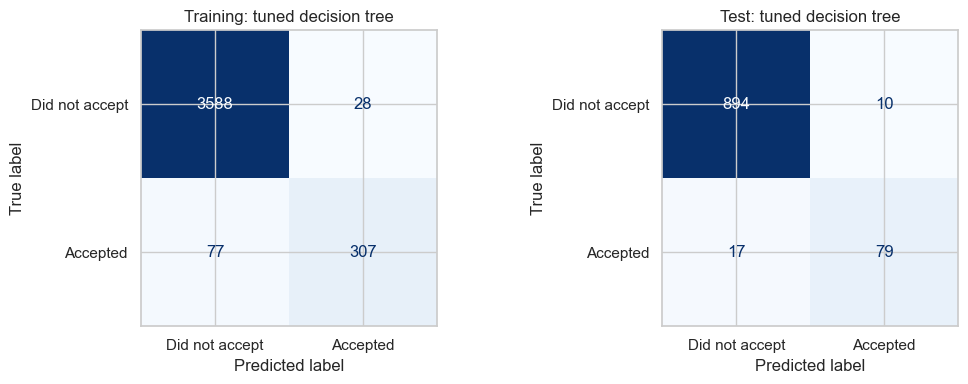


Training and test metrics:
          Accuracy  Precision  Recall     F1  ROC-AUC  Average precision
Dataset                                                                 
Training     0.974      0.916   0.799  0.854    0.987              0.917
Test         0.973      0.888   0.823  0.854    0.982              0.903

Fitted tree depth: 5
Number of leaves: 18
Total nodes: 35


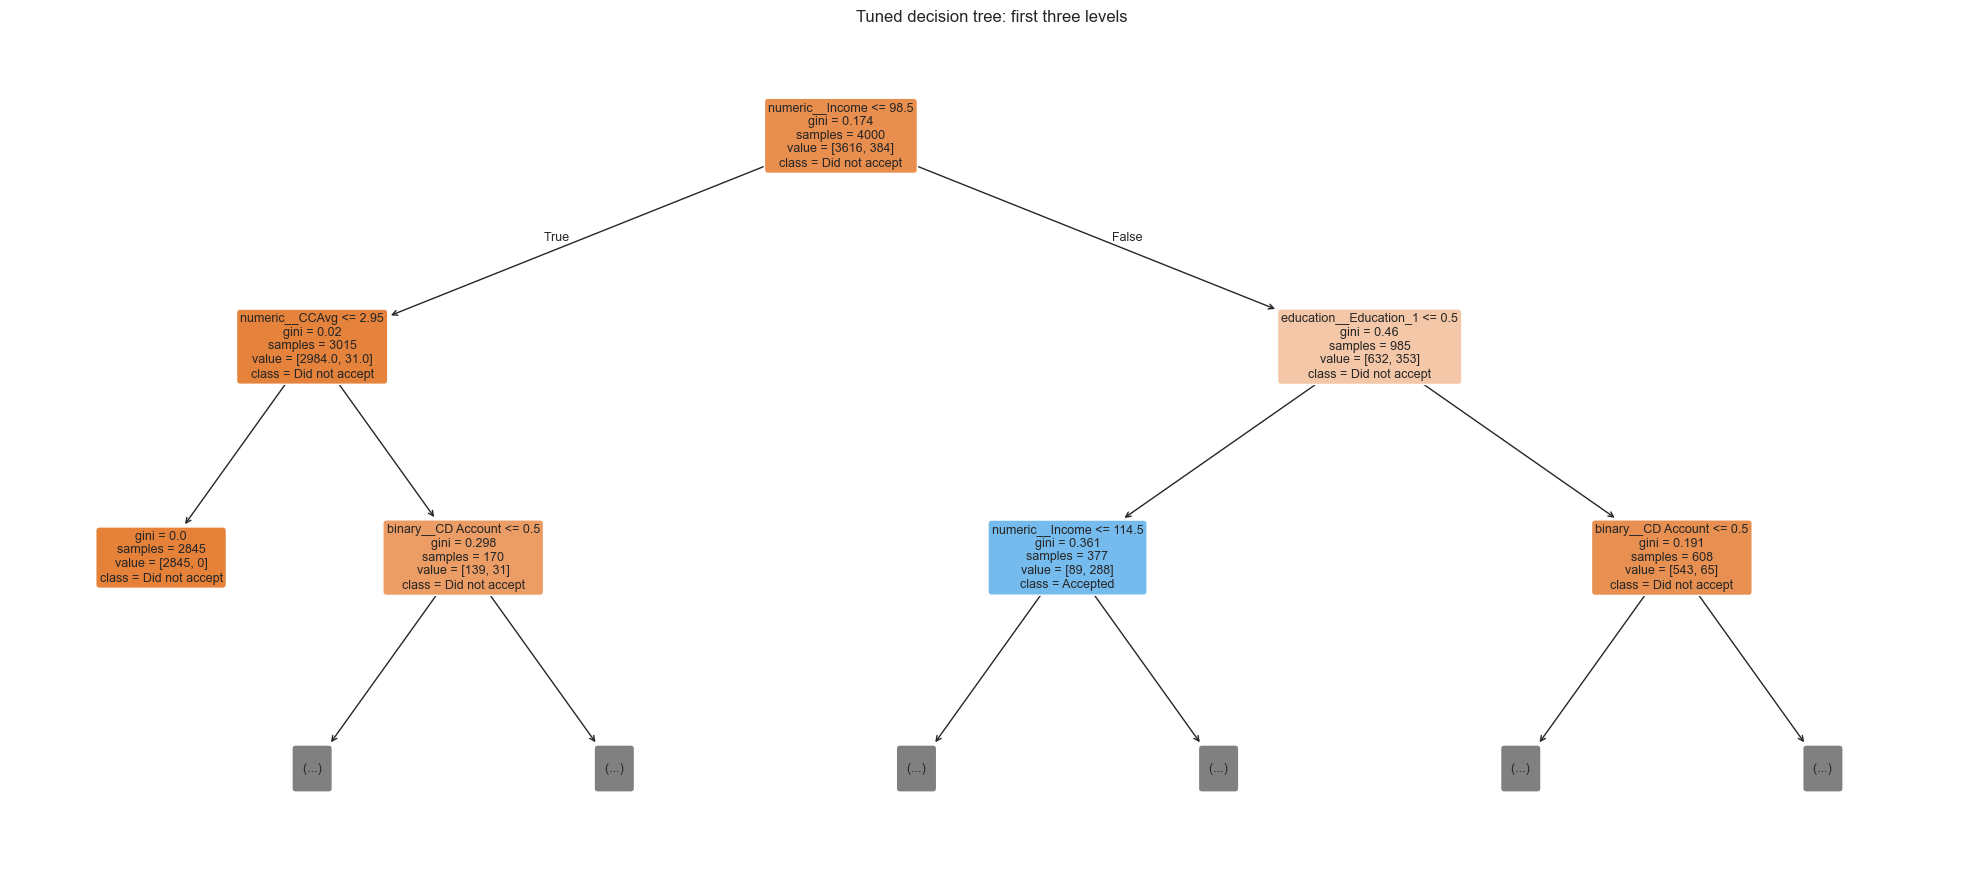

In [ ]:
# Decision Tree Classification with Small Hyperparameter Search
#
# Objective:
# Predict personal loan acceptance using the five selected features
# and find suitable settings for tree complexity.
#
# Approach:
# 1. Prepare continuous, categorical and binary features.
# 2. Search 18 hyperparameter combinations using stratified 10-fold CV.
# 3. Select the model with the highest mean validation average precision.
# 4. Report training and held-out test metrics.
# 5. Plot confusion matrices and the beginning of the fitted tree.
#
# Important:
# - Decision trees do not require feature scaling.
# - Education is one-hot encoded because it represents categories.
# - Preprocessing is fitted separately within each CV training fold.
# - The test set is excluded from hyperparameter tuning.
# - Repeatedly choosing models based on test results can make the
#   test set an unreliable estimate of future performance.
#
# Prerequisite:
# X_train, X_test, y_train and y_test already exist.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

# 1. Select the same features used for logistic regression.
selected_features = [
    "Income",
    "CCAvg",
    "CD Account",
    "Mortgage",
    "Education"
]

X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

# 2. Prepare features. No standardisation is needed for a tree.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

education_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop=None,
        handle_unknown="ignore"
    ))
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, ["Income", "CCAvg", "Mortgage"]),
    ("education", education_pipeline, ["Education"]),
    ("binary", binary_pipeline, ["CD Account"])
])

tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# 3. Search a small grid: 3 × 3 × 2 = 18 combinations.
param_grid = {
    "classifier__max_depth": [3, 5, 8],
    "classifier__min_samples_leaf": [5, 10, 20],
    "classifier__min_samples_split": [2, 20]
}

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="average_precision",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    error_score="raise"
)

search.fit(X_train_selected, y_train)

# GridSearchCV automatically refits the winning pipeline on all training data.
best_tree = search.best_estimator_

print("Best hyperparameters:")
print(search.best_params_)

print(
    "\nBest mean CV average precision:",
    round(search.best_score_, 3)
)

# 4. Show the five best settings and their train/validation AP scores.
cv_results = pd.DataFrame(search.cv_results_)

result_columns = [
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
    "param_classifier__min_samples_split",
    "mean_train_average_precision",
    "mean_test_average_precision",
    "std_test_average_precision"
]

print("\nTop five hyperparameter combinations:")
print(
    cv_results
    .sort_values("rank_test_average_precision")
    [result_columns]
    .head(5)
    .round(3)
    .to_string(index=False)
)

# 5. Evaluate the selected model.
datasets = {
    "Training": (X_train_selected, y_train),
    "Test": (X_test_selected, y_test)
}

metric_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, (X_data, y_data)) in zip(axes, datasets.items()):

    predictions = best_tree.predict(X_data)
    probabilities = best_tree.predict_proba(X_data)[:, 1]

    metric_rows.append({
        "Dataset": name,
        "Accuracy": accuracy_score(y_data, predictions),
        "Precision": precision_score(
            y_data, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_data, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_data, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_data, probabilities),
        "Average precision": average_precision_score(
            y_data, probabilities
        )
    })

    ConfusionMatrixDisplay.from_predictions(
        y_data,
        predictions,
        labels=[0, 1],
        display_labels=["Did not accept", "Accepted"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name}: tuned decision tree")

plt.tight_layout()
plt.show()

print("\nTraining and test metrics:")
print(
    pd.DataFrame(metric_rows)
    .set_index("Dataset")
    .round(3)
)

# 6. Inspect the actual complexity of the fitted tree.
fitted_classifier = best_tree.named_steps["classifier"]

print("\nFitted tree depth:", fitted_classifier.get_depth())
print("Number of leaves:", fitted_classifier.get_n_leaves())
print("Total nodes:", fitted_classifier.tree_.node_count)

# Show only the first three levels to keep the plot readable.
feature_names = (
    best_tree.named_steps["preprocessing"]
    .get_feature_names_out()
)

plt.figure(figsize=(20, 9))

plot_tree(
    fitted_classifier,
    feature_names=list(feature_names),
    class_names=["Did not accept", "Accepted"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)

plt.title("Tuned decision tree: first three levels")
plt.tight_layout()
plt.show()

Best hyperparameters:
{'classifier__max_depth': 5, 'classifier__max_features': 1.0, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 300}

Best mean CV average precision: 0.918

Top five hyperparameter combinations:
 param_classifier__n_estimators param_classifier__max_depth  param_classifier__min_samples_leaf param_classifier__max_features  mean_train_average_precision  mean_test_average_precision  std_test_average_precision
                            300                           5                                   5                            1.0                         0.947                        0.918                       0.032
                            300                        None                                   5                            1.0                         0.974                        0.917                       0.031
                            100                           5                                   5                            1.0  

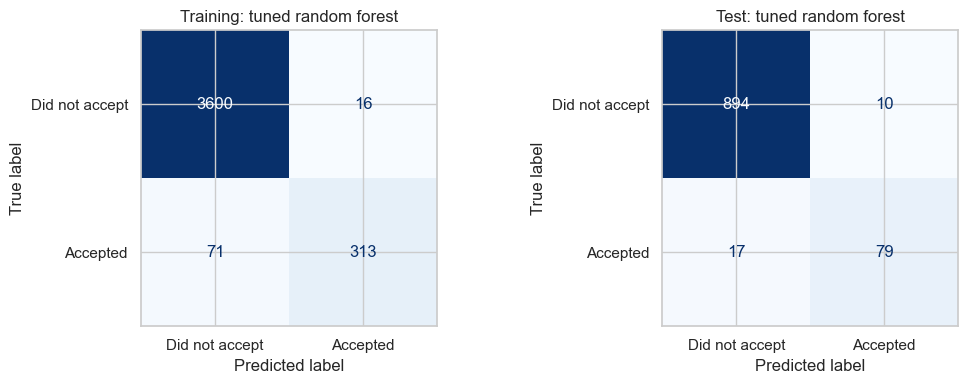


Training and held-out test metrics:
          Accuracy  Precision  Recall     F1  ROC-AUC  Average precision
Dataset                                                                 
Training     0.978      0.951   0.815  0.878    0.991              0.946
Test         0.973      0.888   0.823  0.854    0.986              0.925

Permutation feature importance:
   Feature  Mean_AP_decrease    Std
    Income            0.7471 0.0065
 Education            0.4926 0.0256
     CCAvg            0.0679 0.0074
CD Account            0.0140 0.0032
  Mortgage            0.0071 0.0026


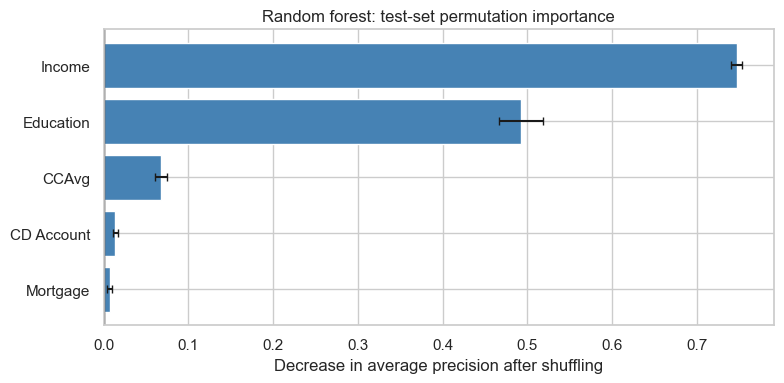

In [19]:
# Random Forest Classification with Small Hyperparameter Search
#
# Objective:
# Predict personal loan acceptance using the five selected features
# and tune a small set of random forest hyperparameters.
#
# Approach:
# 1. Prepare numerical, categorical and binary features.
# 2. Search 16 combinations using stratified 10-fold cross-validation.
# 3. Select the model with the highest validation average precision.
# 4. Report training and held-out test metrics.
# 5. Plot confusion matrices and permutation feature importance.
#
# Important:
# - Random forests do not require feature scaling.
# - Education is one-hot encoded because it represents categories.
# - Preprocessing is fitted separately within each CV training fold.
# - The test set is excluded from hyperparameter tuning.
# - Training performance is in-sample and may be optimistic.
# - Use CV scores for model comparisons; avoid repeatedly choosing
#   models based on held-out test results.
#
# Prerequisite:
# X_train, X_test, y_train and y_test already exist.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

# 1. Select the same features used for the previous models.
selected_features = [
    "Income",
    "CCAvg",
    "CD Account",
    "Mortgage",
    "Education"
]

X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

# 2. Prepare the features without scaling.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

education_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, ["Income", "CCAvg", "Mortgage"]),
    ("education", education_pipeline, ["Education"]),
    ("binary", binary_pipeline, ["CD Account"])
])

rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# 3. Search 2 × 2 × 2 × 2 = 16 combinations.
# GridSearchCV parallelises fits; each forest uses one worker to
# avoid nested parallelism.
param_grid = {
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [5, None],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__max_features": ["sqrt", 1.0]
}

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="average_precision",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    error_score="raise"
)

rf_search.fit(X_train_selected, y_train)

# The winning pipeline is automatically refitted on all training data.
best_rf = rf_search.best_estimator_

print("Best hyperparameters:")
print(rf_search.best_params_)

print(
    "\nBest mean CV average precision:",
    round(rf_search.best_score_, 3)
)

# 4. Display the best five hyperparameter combinations.
cv_results = pd.DataFrame(rf_search.cv_results_)

result_columns = [
    "param_classifier__n_estimators",
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
    "param_classifier__max_features",
    "mean_train_average_precision",
    "mean_test_average_precision",
    "std_test_average_precision"
]

print("\nTop five hyperparameter combinations:")
print(
    cv_results
    .sort_values("rank_test_average_precision")
    [result_columns]
    .head(5)
    .round(3)
    .to_string(index=False)
)

# Report all validation metrics for the winning configuration.
best_index = rf_search.best_index_

cv_summary = pd.DataFrame({
    "Mean": {
        metric: cv_results.loc[best_index, f"mean_test_{metric}"]
        for metric in scoring
    },
    "Std": {
        metric: cv_results.loc[best_index, f"std_test_{metric}"]
        for metric in scoring
    }
})

print("\nCross-validation metrics for the best configuration:")
print(cv_summary.round(3))

# 5. Evaluate training and held-out test predictions.
datasets = {
    "Training": (X_train_selected, y_train),
    "Test": (X_test_selected, y_test)
}

metric_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, (X_data, y_data)) in zip(axes, datasets.items()):

    predictions = best_rf.predict(X_data)
    probabilities = best_rf.predict_proba(X_data)[:, 1]

    metric_rows.append({
        "Dataset": name,
        "Accuracy": accuracy_score(y_data, predictions),
        "Precision": precision_score(
            y_data, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_data, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_data, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_data, probabilities),
        "Average precision": average_precision_score(
            y_data, probabilities
        )
    })

    ConfusionMatrixDisplay.from_predictions(
        y_data,
        predictions,
        labels=[0, 1],
        display_labels=["Did not accept", "Accepted"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name}: tuned random forest")

plt.tight_layout()
plt.show()

rf_metrics = pd.DataFrame(metric_rows).set_index("Dataset")

print("\nTraining and held-out test metrics:")
print(rf_metrics.round(3))

# 6. Permutation importance on the held-out test set.
# Shuffle each original feature and measure the decrease in AP.
# This is for final interpretation, not further test-driven selection.
importance = permutation_importance(
    best_rf,
    X_test_selected,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "Feature": selected_features,
    "Mean_AP_decrease": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Mean_AP_decrease", ascending=False)

print("\nPermutation feature importance:")
print(importance_table.round(4).to_string(index=False))

plot_data = importance_table.sort_values("Mean_AP_decrease")

plt.figure(figsize=(8, 4))

plt.barh(
    plot_data["Feature"],
    plot_data["Mean_AP_decrease"],
    xerr=plot_data["Std"],
    color="steelblue",
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Decrease in average precision after shuffling")
plt.title("Random forest: test-set permutation importance")
plt.tight_layout()
plt.show()

Mean cross-validation scores:
                     Accuracy  Precision  Recall     F1  ROC-AUC  \
Logistic regression     0.954      0.863   0.626  0.723    0.952   
Decision tree           0.968      0.896   0.761  0.820    0.980   
Random forest           0.972      0.923   0.779  0.841    0.985   

                     Average precision  
Logistic regression              0.821  
Decision tree                    0.899  
Random forest                    0.918  

Cross-validation standard deviations:
                     Accuracy  Precision  Recall     F1  ROC-AUC  \
Logistic regression     0.012      0.073   0.092  0.080    0.016   
Decision tree           0.008      0.052   0.074  0.048    0.010   
Random forest           0.008      0.061   0.080  0.050    0.007   

                     Average precision  
Logistic regression              0.065  
Decision tree                    0.040  
Random forest                    0.032  

Mean training scores:
                     Accuracy  Pre

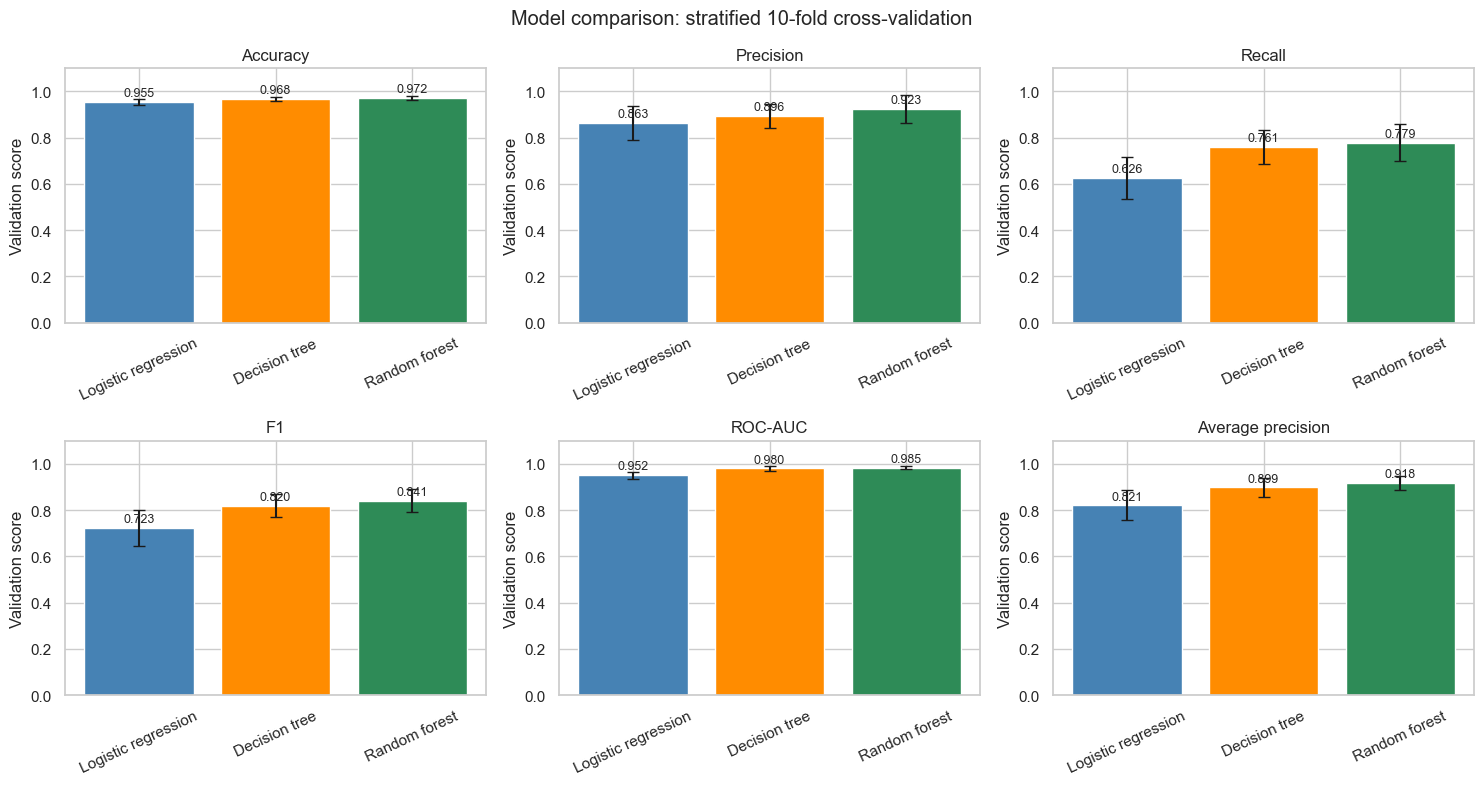


Models ranked by mean validation average precision:
                     Accuracy  Precision  Recall     F1  ROC-AUC  \
Random forest           0.972      0.923   0.779  0.841    0.985   
Decision tree           0.968      0.896   0.761  0.820    0.980   
Logistic regression     0.954      0.863   0.626  0.723    0.952   

                     Average precision  
Random forest                    0.918  
Decision tree                    0.899  
Logistic regression              0.821  


In [20]:
# Compare Logistic Regression, Decision Tree and Random Forest
#
# Objective:
# Compare classification performance using the same selected features
# and identical stratified 10-fold cross-validation splits.
#
# Prerequisites:
# - model: logistic regression pipeline from the earlier code.
# - best_tree: tuned decision tree pipeline.
# - best_rf: tuned random forest pipeline.
# - X_train_selected and y_train: training features and target.
#
# Interpretation:
# - Higher scores are better for all metrics shown.
# - Standard deviations describe variation between validation folds.
# - Training scores help identify possible overfitting.
#
# Limitation:
# The tree and forest settings were selected using this training data.
# Re-evaluating those settings on the same CV folds is not an independent
# assessment of the tuning procedure. Nested CV would be needed for that.
# This comparison does not use the held-out test set.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# clone() preserves model settings but removes previously fitted state.
models = {
    "Logistic regression": clone(model),
    "Decision tree": clone(best_tree),
    "Random forest": clone(best_rf)
}

# Create splits once so every model uses identical validation customers.
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

splits = list(cv.split(X_train_selected, y_train))

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc",
    "Average precision": "average_precision"
}

validation_means = {}
validation_stds = {}
training_means = {}
fold_results = []

for name, estimator in models.items():

    results = cross_validate(
        estimator,
        X_train_selected,
        y_train,
        cv=splits,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise"
    )

    validation_means[name] = {
        metric: results[f"test_{metric}"].mean()
        for metric in scoring
    }

    validation_stds[name] = {
        metric: results[f"test_{metric}"].std()
        for metric in scoring
    }

    training_means[name] = {
        metric: results[f"train_{metric}"].mean()
        for metric in scoring
    }

    # Retain individual fold scores for inspecting variability.
    for fold in range(10):
        fold_results.append({
            "Model": name,
            "Fold": fold + 1,
            **{
                metric: results[f"test_{metric}"][fold]
                for metric in scoring
            }
        })

# Tables: rows are models, columns are metrics.
cv_means = pd.DataFrame(validation_means).T
cv_stds = pd.DataFrame(validation_stds).T
train_means = pd.DataFrame(training_means).T
fold_results = pd.DataFrame(fold_results)

print("Mean cross-validation scores:")
print(cv_means.round(3))

print("\nCross-validation standard deviations:")
print(cv_stds.round(3))

print("\nMean training scores:")
print(train_means.round(3))

# Compare training and validation AP to inspect possible overfitting.
ap_comparison = pd.DataFrame({
    "Training AP": train_means["Average precision"],
    "Validation AP": cv_means["Average precision"]
})

ap_comparison["Gap"] = (
    ap_comparison["Training AP"] - ap_comparison["Validation AP"]
)

print("\nTraining–validation average precision comparison:")
print(ap_comparison.round(3))

# Plot each metric separately.
# Error bars show ±1 standard deviation across validation folds.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

colors = ["steelblue", "darkorange", "seagreen"]

for ax, metric in zip(axes.flat, scoring):

    ax.bar(
        cv_means.index,
        cv_means[metric],
        yerr=cv_stds[metric],
        color=colors,
        capsize=4
    )

    ax.set_title(metric)
    ax.set_ylabel("Validation score")
    ax.set_ylim(0, 1.1)
    ax.tick_params(axis="x", rotation=25)

    for position, value in enumerate(cv_means[metric]):
        ax.text(
            position,
            value + 0.025,
            f"{value:.3f}",
            ha="center",
            fontsize=9
        )

plt.suptitle("Model comparison: stratified 10-fold cross-validation")
plt.tight_layout()
plt.show()

print("\nModels ranked by mean validation average precision:")
print(
    cv_means.sort_values("Average precision", ascending=False)
    .round(3)
)